In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypuf
import sys

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PUF library:", pypuf.__file__)

print("\nAll libraries imported successfully!")

Python: 3.14.8 (v3.14.8:8e6e75d9102, Sep 30 2026, 14:34:30) [Clang 21.0.0 (clang-2100.1.1.101)]
NumPy: 2.5.5
Pandas: 3.1.1
PUF library: /Users/mj/University/System_Security_Assignment_2/.venv/lib/python3.14/site-packages/pypuf/__init__.py

All libraries imported successfully!


In [20]:
from pypuf.simulation import ArbiterPUF
import inspect

print("Arbiter PUF class:", ArbiterPUF)

print("\nConstructor:")
print(inspect.signature(ArbiterPUF))

print("\nAvailable methods:")
print([method for method in dir(ArbiterPUF) if not method.startswith("_")])

Arbiter PUF class: <class 'pypuf.simulation.delay.ArbiterPUF'>

Constructor:
(n: int, seed: int = None, transform: Callable | str = None, noisiness: float = 0) -> None

Available methods:
['att', 'att_inverse', 'biased', 'chain', 'challenge_length', 'combiner_xor', 'efba_bit', 'eval', 'eval_block', 'generate_concatenated_transform', 'generate_stacked_transform', 'k', 'ltf_count', 'ltf_eval', 'n', 'normal_weights', 'r_eval', 'response_length', 'seed', 'sigma_noise_from_random_weights', 'transform_atf', 'transform_id', 'val']


In [21]:
from pypuf.simulation import ArbiterPUF
import inspect

print("Arbiter PUF class:", ArbiterPUF)

print("\nConstructor:")
print(inspect.signature(ArbiterPUF))

print("\nAvailable methods:")
print([
    method for method in dir(ArbiterPUF)
    if not method.startswith("_")
])

Arbiter PUF class: <class 'pypuf.simulation.delay.ArbiterPUF'>

Constructor:
(n: int, seed: int = None, transform: Callable | str = None, noisiness: float = 0) -> None

Available methods:
['att', 'att_inverse', 'biased', 'chain', 'challenge_length', 'combiner_xor', 'efba_bit', 'eval', 'eval_block', 'generate_concatenated_transform', 'generate_stacked_transform', 'k', 'ltf_count', 'ltf_eval', 'n', 'normal_weights', 'r_eval', 'response_length', 'seed', 'sigma_noise_from_random_weights', 'transform_atf', 'transform_id', 'val']


In [22]:
from pypuf.simulation import ArbiterPUF

# Configuring  PUF
N = 64
SEED = 42

# Create Arbiter PUF
puf = ArbiterPUF(
    n=N,
    seed=SEED,
    noisiness=0
)

print("PUF created successfully!")
print("Challenge length:", puf.challenge_length)
print("Response length:", puf.response_length)
print("PUF seed:", puf.seed)

PUF created successfully!
Challenge length: 64
Response length: 1
PUF seed: <function Simulation.seed at 0x1141c7110>


In [23]:
import numpy as np

# Reproducible random challenge generation
rng = np.random.default_rng(42)

NUM_CRPS = 10000

# Generating 10,000 challenges, each containing 64 bits
challenges = rng.choice(
    [-1, 1],
    size=(NUM_CRPS, N)
)

print("Challenges generated:", len(challenges))
print("Challenge shape:", challenges.shape)

print("\nFirst 5 challenges:")
print(challenges[:5])

Challenges generated: 10000
Challenge shape: (10000, 64)

First 5 challenges:
[[-1  1  1 -1 -1  1 -1  1 -1 -1  1  1  1  1  1  1  1 -1  1 -1  1 -1 -1  1
   1  1 -1  1  1 -1 -1 -1 -1  1  1 -1  1  1 -1  1 -1  1  1 -1 -1  1 -1  1
   1  1  1 -1 -1 -1 -1 -1  1 -1  1  1  1  1 -1  1]
 [-1 -1  1 -1 -1 -1  1 -1 -1 -1  1 -1 -1 -1  1  1  1 -1 -1  1  1  1 -1 -1
   1  1 -1  1  1 -1  1 -1 -1  1  1 -1  1 -1  1 -1  1  1  1  1 -1  1 -1  1
   1 -1  1  1 -1 -1 -1 -1 -1  1  1 -1  1  1 -1  1]
 [ 1  1  1  1 -1  1  1 -1  1 -1 -1 -1  1 -1 -1 -1  1  1 -1 -1  1 -1  1 -1
   1 -1 -1  1 -1  1  1  1  1  1 -1 -1 -1  1 -1 -1 -1 -1 -1 -1  1  1  1 -1
   1 -1  1  1  1 -1 -1  1 -1 -1 -1 -1 -1 -1  1  1]
 [ 1 -1  1 -1 -1 -1 -1  1 -1  1 -1  1 -1 -1  1  1 -1  1 -1  1  1 -1  1 -1
  -1 -1 -1  1 -1 -1  1 -1  1 -1  1  1  1 -1 -1  1 -1  1 -1  1  1 -1 -1  1
  -1  1 -1  1  1 -1  1 -1  1 -1 -1 -1 -1 -1  1 -1]
 [ 1 -1 -1  1  1 -1 -1  1  1  1 -1 -1  1  1 -1 -1 -1  1 -1 -1 -1  1 -1 -1
  -1 -1  1 -1 -1  1 -1  1  1 -1  1 -1  1 -1  1  1  1

In [24]:
# Passing challenges through the physical PUF simulation
responses = puf.eval(challenges)

print("Responses generated:", len(responses))
print("Response shape:", responses.shape)

print("\nFirst 10 responses:")
print(responses[:10])

Responses generated: 10000
Response shape: (10000,)

First 10 responses:
[-1 -1 -1 -1  1  1 -1 -1 -1 -1]


In [25]:
import pandas as pd

# Converting challenges into readable binary strings
challenge_strings = [
    ''.join('1' if bit == 1 else '0' for bit in challenge)
    for challenge in challenges
]

# Converting responses into binary values
response_values = np.asarray(responses).reshape(-1)

response_values = [
    1 if response == 1 else 0
    for response in response_values
]

# Creating dataset
df = pd.DataFrame({
    "challenge": challenge_strings,
    "response": response_values
})

print(df.head())
print("\nDataset shape:", df.shape)

                                           challenge  response
0  0110010100111111101010011101100001101101011001...         0
1  0010001000100011100111001101101001101010111101...         0
2  1111011010001000110010101001011111000100000011...         0
3  1010000101010011010110100001001010111001010110...         0
4  1001100111001100010001000010010110101011100001...         1

Dataset shape: (10000, 2)


In [ ]:
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "02_Notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATASET_DIR = PROJECT_DIR / "03_Datasets"
RESULTS_DIR = PROJECT_DIR / "04_Results"
GRAPHS_DIR = PROJECT_DIR / "05_Graphs"

for folder in [DATASET_DIR, RESULTS_DIR, GRAPHS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

output_file = DATASET_DIR / "arbiter_puf_64bit_10000_crps.csv"

df.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print(output_file)

Dataset saved successfully!
/Users/mj/University/System_Software_Security_2/03_Datasets/arbiter_puf_64bit_10000_crps.csv


Experiment


In [27]:
from sklearn.model_selection import train_test_split

# Converting binary challenge strings into numerical features
X = np.array([
    [int(bit) for bit in challenge]
    for challenge in df["challenge"]
])

y = df["response"].to_numpy()

# Splitting dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Challenge features:", X_train.shape[1])

Training samples: 8000
Testing samples: 2000
Challenge features: 64


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

# Initializingmodel
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Measuring training time
start_time = time.perf_counter()

lr_model.fit(X_train, y_train)

training_time = time.perf_counter() - start_time

print("Logistic Regression training completed!")
print("Training time:", round(training_time, 4), "seconds")

Logistic Regression training completed!
Training time: 0.0038 seconds


In [29]:
# Predicting responses for unseen challenges
y_pred = lr_model.predict(X_test)

# Calculating accuracy
lr_accuracy = accuracy_score(y_test, y_pred)

print("Actual responses:    ", y_test[:20])
print("Predicted responses: ", y_pred[:20])

print("\nLogistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("Training time:",
      round(training_time, 4), "seconds")

Actual responses:     [0 1 0 1 0 0 1 1 1 1 0 0 0 1 0 0 1 1 0 1]
Predicted responses:  [0 1 1 1 0 1 1 0 1 1 0 1 1 0 0 0 0 1 0 1]

Logistic Regression Accuracy: 54.9 %
Training time: 0.0038 seconds


FileNotFoundError: [Errno 2] No such file or directory: '/Users/mj/University/System_Software_Security_2/05_Graphs/lr_accuracy.png'

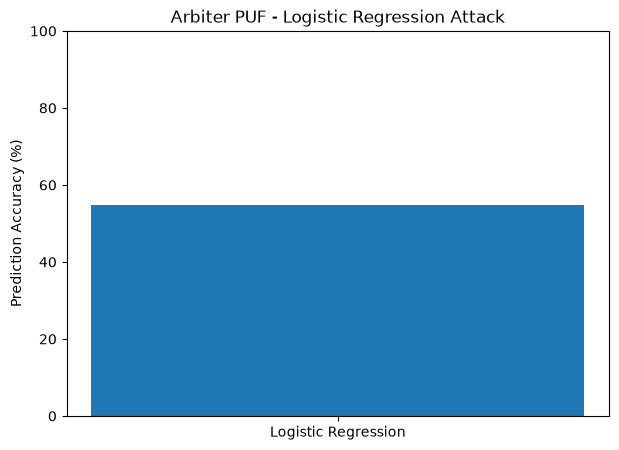

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    ["Logistic Regression"],
    [lr_accuracy * 100]
)

plt.ylabel("Prediction Accuracy (%)")
plt.title("Arbiter PUF - Logistic Regression Attack")
plt.ylim(0, 100)

plt.savefig(
    PROJECT_DIR / "05_Graphs" / "lr_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
results = pd.DataFrame([{
    "PUF": "Arbiter PUF",
    "Challenge_Length": 64,
    "CRPs": 10000,
    "Model": "Logistic Regression",
    "Accuracy": lr_accuracy,
    "Training_Time_Seconds": training_time
}])

results.to_csv(
    PROJECT_DIR / "04_Results" / "lr_results.csv",
    index=False
)

print(results)

           PUF  Challenge_Length   CRPs                Model  Accuracy  \
0  Arbiter PUF                64  10000  Logistic Regression     0.549   

   Training_Time_Seconds  
0               0.008367  


Experiment 2B: Logistic Regression with Arbiter Feature Transformation

In [ ]:
# Use original bipolar challenges (-1, +1)
X_bipolar = challenges.copy()

# Arbiter PUF feature transformation
X_transformed = np.flip(
    np.cumprod(
        np.flip(X_bipolar, axis=1),
        axis=1
    ),
    axis=1
)

print("Original challenge:")
print(X_bipolar[0][:10])

print("\nTransformed challenge:")
print(X_transformed[0][:10])

print("\nShape:", X_transformed.shape)

Original challenge:
[-1  1  1 -1 -1  1 -1  1 -1 -1]

Transformed challenge:
[ 1 -1 -1 -1  1 -1 -1  1  1 -1]

Shape: (10000, 64)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

# Usingthe same held-out split as the original experiment
X_train_phi, X_test_phi, y_train_phi, y_test_phi = train_test_split(
    X_transformed,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

lr_phi = LogisticRegression(
    max_iter=3000,
    random_state=42
)

start = time.perf_counter()

lr_phi.fit(X_train_phi, y_train_phi)

lr_phi_time = time.perf_counter() - start

y_pred_phi = lr_phi.predict(X_test_phi)

lr_phi_accuracy = accuracy_score(
    y_test_phi,
    y_pred_phi
)

print("Transformed LR accuracy:",
      round(lr_phi_accuracy * 100, 2), "%")

print("Training time:",
      round(lr_phi_time, 4), "seconds")

Transformed LR accuracy: 98.95 %
Training time: 0.0032 seconds


In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "LR - Raw Challenges",
        "LR - Transformed Challenges"
    ],
    "Accuracy (%)": [
        lr_accuracy * 100,
        lr_phi_accuracy * 100
    ],
    "Training Time (s)": [
        training_time,
        lr_phi_time
    ]
})

display(comparison)

,Model,Accuracy (%),Training Time (s)
0,LR - Raw Challenges,54.90,0.008367
1,LR - Transformed Challenges,98.95,0.003211


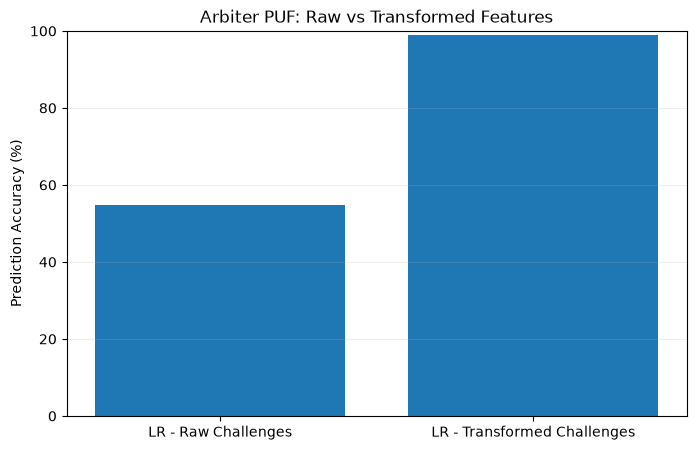

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy (%)"]
)

plt.ylabel("Prediction Accuracy (%)")
plt.title("Arbiter PUF: Raw vs Transformed Features")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.2)

plt.savefig(
    PROJECT_DIR / "05_Graphs" / "lr_feature_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
comparison.to_csv(
    PROJECT_DIR / "04_Results" / "lr_feature_comparison.csv",
    index=False
)

print("Comparison results saved!")

Comparison results saved!
